# Detecting illicit Bitcoin transactions: final submission notebook

This notebook rebuilds both of my selections for the private leaderboard from the raw competition files (Blend 2 and XGB-NBR), and compares them with the models they were built from.

My main submission is a 50/50 rank blend of a random forest and an XGBoost model that uses five extra features built from the transaction graph. To make those features, a first XGBoost model scores every transaction, and the scores are then summarised over each transaction's neighbours (mean and max).

All five models below are trained and evaluated on the same validation folds:

| Model | Description |
|---|---|
| XGB-165 | XGBoost on the 165 provided features |
| RF-165 | Random forest on the 165 provided features |
| XGB-NBR | XGBoost on the 165 features + 5 neighbour features (**final selection 2**) |
| Blend 1 | Rank blend of XGB-165 and RF-165 (my earlier best submission) |
| Blend 2 | Rank blend of XGB-NBR and RF-165 (**final selection 1**) |

| Model | CV objective | Holdout AUC | Public LB | Private LB |
|---|---|---|---|---|
| XGB-165 | 0.9612 | 0.9981 | 0.95402 | 0.94621 |
| RF-165 | 0.9667 | 0.9972 | - | - |
| XGB-NBR | 0.9630 | 0.9985 | 0.95557 | 0.94865 |
| Blend 1 | 0.9653 | 0.9979 | 0.95533 | 0.94786 |
| **Blend 2** | 0.9663 | 0.9982 | **0.95631** | **0.94912** |

The hyperparameters in this notebook are hardcoded as rerunning the hyperparameter tuning of all the models in this notebook would prove too time consuming. The hyperparameters were tuned in prior notebooks with Optuna (TPE sampler) on the same walk-forward CV objective used here.

## 1. Setup

In [1]:
import platform

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score,
    recall_score, matthews_corrcoef, confusion_matrix, precision_recall_curve,
)
from scipy.stats import rankdata, spearmanr, ks_2samp, binomtest
from IPython.display import display

FOUND_VERSIONS = {"xgboost": xgb.__version__, "sklearn": sklearn.__version__,
                  "numpy": np.__version__, "pandas": pd.__version__}
print(f"python {platform.python_version()} | " + " | ".join(f"{k} {v}" for k, v in FOUND_VERSIONS.items()))

python 3.13.16 | xgboost 3.4.1 | sklearn 1.9.1 | numpy 2.5.3 | pandas 3.0.6


In [2]:
# ---------------------------------------------------------------- paths
DATA_DIR = "../data"

# Output files for my two selections for the private leaderboard
SUBMISSION_FILES = {"Blend 2": "submission_blend2.csv", "XGB-NBR": "submission_xgb_nbr.csv"}


# ---------------------------------------------------------------- seeds and validation
SEED = 42
SEEDS = [42, 43, 44, 45, 46]       # seeds averaged for every model
STAGE1_SEEDS = [42, 43, 44]        # seeds for the stage-1 scores

HOLDOUT_START = 31                 # steps 31-35: holdout; steps 1-30: development
# Expanding walk-forward folds: (last training step, first validation step, last validation step)
FOLD_DEFS = [(14, 15, 18), (18, 19, 22), (22, 23, 26), (26, 27, 30)]
STD_PENALTY = 0.5                  # CV objective = mean fold AUC - 0.5 x std fold AUC

# ---------------------------------------------------------------- XGBoost training procedure
ES_STEPS = 2                       # the last 2 steps of each training window form the early-stopping set
ES_PATIENCE = 100
MAX_ROUNDS = 5000
MIN_ROUNDS_WARN = 50
ROUND_SCALE_CAP = 1.25             # refit rounds = best_rounds x min(n_full / n_inner, 1.25)
FALLBACK_ROUNDS = 200              # stage 1 only, for tiny windows with one class in the early-stopping steps
N_BLOCKS = 5                       # stage-1 out-of-fold scoring: time blocks per window

XGB_BASE_PARAMS = {"objective": "binary:logistic", "eval_metric": "auc", "tree_method": "hist", "n_jobs": -1}

# ---------------------------------------------------------------- hyperparameters (hardcoded; tuned beforehand with Optuna)
# spw_mode / cw_mode = "full": the illicit class is weighted by r = licit:illicit ratio of the training rows.

# XGB-165, also used as the stage-1 model for the neighbour features
S1_PARAMS = {
    "learning_rate": 0.05, "max_depth": 10, "min_child_weight": 2.3341414554638376,
    "subsample": 0.9497862564911337, "colsample_bytree": 0.5832815398449073,
    "reg_lambda": 0.28689876199114767, "reg_alpha": 0.002057268125514701,
    "gamma": 9.535266701331619, "spw_mode": "full",
}

# XGB-NBR (stage 2: 165 features + 5 neighbour features)
S2_PARAMS = {
    "learning_rate": 0.05, "max_depth": 10, "min_child_weight": 7.613460816650711,
    "subsample": 0.9999237181078184, "colsample_bytree": 0.4726353774131145,
    "reg_lambda": 0.15784212246799978, "reg_alpha": 0.5529752671017932,
    "gamma": 9.342966043088595, "spw_mode": "full",
}

# RF-165
RF_BASE_PARAMS = {"bootstrap": True, "n_jobs": -1}
RF_PARAMS = {
    "max_features": 0.6890992439809974, "min_samples_leaf": 12, "max_depth": 24,
    "max_samples": 0.5767546787297703, "criterion": "entropy", "cw_mode": "full",
}
RF_N_TREES = 500

# Blends
BLEND_W_XGB = 0.5                                   # weight on the XGBoost model; 1 - w on RF-165
WEIGHT_GRID = [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
BLEND_TIE_TOL = 0.001                               # a weight must beat 0.5 by at least this ...
N_BOOT = 2000                                       # ... and its step-bootstrap interval must lie above zero

# Leaderboard scores from Kaggle (public, private)
LEADERBOARD = {"XGB-165": (0.95402, 0.94621), "XGB-NBR": (0.95557, 0.94865),
               "Blend 1": (0.95533, 0.94786), "Blend 2": (0.95631, 0.94912)}

## 2. Data

`train.csv` has steps 1-35, with `label` = 1 (illicit), 0 (licit) or empty (unknown). `test.csv` has steps 36-49. `txs_edgelist.csv` lists directed edges `txId1 -> txId2` (an output of `txId1` is spent by `txId2`).

In [3]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
edges = pd.read_csv(f"{DATA_DIR}/txs_edgelist.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
sample_sub.columns = sample_sub.columns.str.strip()      # the provided header contains a stray space

FEATURES = [c for c in train.columns if c.startswith("feat_")]
assert len(FEATURES) == 165
assert [c for c in test.columns if c.startswith("feat_")] == FEATURES
assert pd.concat([train["txId"], test["txId"]]).is_unique, "txId must identify one transaction"
assert (test["index"].to_numpy() == sample_sub["index"].to_numpy()).all(), "test rows must follow sample_submission"

n_lab = int(train["label"].notna().sum())
print(f"train: {len(train):,} rows ({n_lab:,} labelled, {len(train) - n_lab:,} unknown), "
      f"steps {train.time_step.min()}-{train.time_step.max()}")
print(f"test:  {len(test):,} rows, steps {test.time_step.min()}-{test.time_step.max()}")
print(f"edges: {len(edges):,}")
print(f"train.csv sorted by time_step: {bool(train['time_step'].is_monotonic_increasing)} ")

train: 141,772 rows (31,235 labelled, 110,537 unknown), steps 1-35
test:  15,329 rows, steps 36-49
edges: 234,355
train.csv sorted by time_step: True 


## 3. Preprocessing

Not much is needed. Both model types are tree ensembles, so nothing is scaled, and missing values are counted below. Only labelled rows are used for training. `time_step` is only used to split the data, since the test steps are outside the training range, and `txId` is just an identifier.

About 12% of labelled transactions are illicit. Instead of resampling, each model up-weights the illicit class by r, the licit:illicit ratio of its training rows (`scale_pos_weight` in XGBoost, `class_weight` in the random forest).

In [4]:
# Labelled rows sorted by time step (RF-165 and the blends use this row order)
labeled = (train[train["label"].notna()]
           .sort_values("time_step", kind="stable")
           .reset_index(drop=True))
labeled["label"] = labeled["label"].astype(int)

dev = labeled[labeled["time_step"] < HOLDOUT_START].reset_index(drop=True)     # steps 1-30
hold = labeled[labeled["time_step"] >= HOLDOUT_START].reset_index(drop=True)   # steps 31-35

n_nan = int(labeled[FEATURES].isna().sum().sum()) + int(test[FEATURES].isna().sum().sum())
print(f"Missing values in the provided features (labelled + test): {n_nan}")
for name, df in [("All labelled (1-35)", labeled), ("Development (1-30)", dev), ("Holdout (31-35)", hold)]:
    print(f"{name:<20} {len(df):>6,} rows | {df['label'].sum():>5,} illicit ({df['label'].mean():.3f})")

Missing values in the provided features (labelled + test): 0
All labelled (1-35)  31,235 rows | 3,644 illicit (0.117)
Development (1-30)   26,905 rows | 2,954 illicit (0.110)
Holdout (31-35)       4,330 rows |   690 illicit (0.159)


## 4. Validation

The test set comes after the training data in time and the features drift over time, so I validate by time instead of using random folds. There are four expanding walk-forward folds on steps 1-30, and steps 31-35 are a holdout that I only scored once per model.

| Window | Train | Evaluate |
|---|---|---|
| Fold 1 | 1-14 | 15-18 |
| Fold 2 | 1-18 | 19-22 |
| Fold 3 | 1-22 | 23-26 |
| Fold 4 | 1-26 | 27-30 |
| Holdout | 1-30 | 31-35 |
| Final | 1-35 | 36-49 (test) |

Models are compared on mean fold AUC - 0.5 x std of the fold AUCs, which penalises models that are good on average but unstable across periods. For XGBoost, early stopping uses the last 2 steps of each training window (never the validation steps), and the model is then refit on the whole window with the number of rounds scaled up for the extra data (capped at 1.25x). All predictions are averaged over 5 seeds.

In [5]:
FOLD_NAMES = [f"fold{k}" for k in range(1, len(FOLD_DEFS) + 1)]
LAST_TRAIN_STEP = int(train["time_step"].max())
TRAIN_STEPS = np.sort(train["time_step"].unique())
TEST_STEPS = np.sort(test["time_step"].unique())

# window name -> (last training step, prediction steps)
WINDOWS = {f"fold{k}": (te, np.arange(vs, ve + 1)) for k, (te, vs, ve) in enumerate(FOLD_DEFS, start=1)}
WINDOWS["holdout"] = (HOLDOUT_START - 1, np.arange(HOLDOUT_START, LAST_TRAIN_STEP + 1))
WINDOWS["final"] = (LAST_TRAIN_STEP, TEST_STEPS)

steps_dev = dev["time_step"].to_numpy()
for name, (te, ps) in WINDOWS.items():
    tr_n = int((labeled["time_step"] <= te).sum())
    if name == "final":
        print(f"{name:>8}: train 1-{te} ({tr_n:,} rows) -> test steps {ps.min()}-{ps.max()} ({len(test):,} rows)")
    else:
        va = labeled["time_step"].isin(ps)
        print(f"{name:>8}: train 1-{te} ({tr_n:,} rows) -> validate {ps.min()}-{ps.max()} "
              f"({int(va.sum()):,} rows, {int(labeled.loc[va, 'label'].sum())} illicit)")

   fold1: train 1-14 (14,896 rows) -> validate 15-18 (2,348 rows, 426 illicit)
   fold2: train 1-18 (17,244 rows) -> validate 19-22 (4,049 rows, 598 illicit)
   fold3: train 1-22 (21,293 rows) -> validate 23-26 (3,424 rows, 404 illicit)
   fold4: train 1-26 (24,717 rows) -> validate 27-30 (2,188 rows, 521 illicit)
 holdout: train 1-30 (26,905 rows) -> validate 31-35 (4,330 rows, 690 illicit)
   final: train 1-35 (31,235 rows) -> test steps 36-49 (15,329 rows)


In [6]:
# Metrics and CV summaries
def fold_summary(y_list, p_list):
    """Fold AUCs and the CV objective from per-fold (labels, predictions)."""
    fold_aucs = np.array([roc_auc_score(y, p) for y, p in zip(y_list, p_list)])
    return {"fold_aucs": fold_aucs,
            "mean_auc": fold_aucs.mean(), "std_auc": fold_aucs.std(),        # population std (ddof=0)
            "objective": fold_aucs.mean() - STD_PENALTY * fold_aucs.std(),
            "worst_fold_auc": fold_aucs.min(),
            "oof_y": np.concatenate(y_list), "oof_p": np.concatenate(p_list)}


def summarise(name, res):
    print(f"{name}: per-fold ROC AUC {np.round(res['fold_aucs'], 4)} | mean {res['mean_auc']:.4f} "
          f"+/- {res['std_auc']:.4f} | objective {res['objective']:.4f}")


def best_f1_threshold(y_true, p):
    """Threshold maximising illicit-class F1 (diagnostic only; the competition metric is threshold-free)."""
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return thresholds[i], f1[i]


def evaluate(y_true, p, threshold):
    y_hat = (p >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y_true, p), "pr_auc": average_precision_score(y_true, p),
            "f1_illicit": f1_score(y_true, y_hat, zero_division=0),
            "precision_illicit": precision_score(y_true, y_hat, zero_division=0),
            "recall_illicit": recall_score(y_true, y_hat, zero_division=0),
            "mcc": matthews_corrcoef(y_true, y_hat)}


def per_step_auc(y_true, p, steps):
    df = pd.DataFrame({"y": np.asarray(y_true), "p": p, "time_step": np.asarray(steps)})
    return pd.DataFrame([{"time_step": s, "n": len(g), "n_illicit": int(g.y.sum()),
                          "roc_auc": roc_auc_score(g.y, g.p) if g.y.nunique() == 2 else np.nan}
                         for s, g in df.groupby("time_step")]).set_index("time_step")

## 5. Neighbour features

### 5.1 Why

The EDA showed that the graph is homophilic: illicit transactions connect to other illicit transactions far more often than chance. But edges never cross time steps and the test steps have no labels, so no test transaction has a labelled neighbour. Instead of neighbours' labels, I use their predicted scores, which exist for every transaction. The statistics below describe the training labels.

In [7]:
lab_map = train.set_index("txId")["label"]          # NaN for unknown transactions; test txIds are absent
step_map = pd.concat([train.set_index("txId")["time_step"], test.set_index("txId")["time_step"]])

# Labelled-labelled edges (each directed edge once)
le = edges.assign(l1=edges["txId1"].map(lab_map), l2=edges["txId2"].map(lab_map)).dropna(subset=["l1", "l2"])
# Undirected view: every labelled-labelled edge seen from both endpoints
und = pd.DataFrame({"node": np.r_[le["l1"], le["l2"]], "nbr": np.r_[le["l2"], le["l1"]]})

base_rate = labeled["label"].mean()
p_ii = und.loc[und["node"] == 1, "nbr"].mean()
p_li = und.loc[und["node"] == 0, "nbr"].mean()
print(f"Illicit share among labelled transactions: {base_rate:.3f}")
print(f"P(neighbour illicit | transaction illicit) = {p_ii:.3f}  (lift {p_ii / base_rate:.1f}x)")
print(f"P(neighbour illicit | transaction licit)   = {p_li:.3f}")

# Homophily test from the course (cross-label edge share r vs 2xy expected under random labels)
y_ill = base_rate
expected_cross = 2 * (1 - y_ill) * y_ill
n_cross = int((le["l1"] != le["l2"]).sum())
r_obs = n_cross / len(le)
p_val = binomtest(n_cross, len(le), expected_cross, alternative="less").pvalue
print(f"Cross-label edge share r = {r_obs:.4f} vs expected 2xy = {expected_cross:.4f} "
      f"(r / 2xy = {r_obs / expected_cross:.3f}, one-sided binomial p = {p_val:.1e}) -> homophilic")

# Edges never cross time steps, so test transactions (steps 36-49) cannot have labelled neighbours
s1, s2 = edges["txId1"].map(step_map), edges["txId2"].map(step_map)
both = s1.notna() & s2.notna()
print(f"Edges within a single time step: {(s1[both] == s2[both]).mean():.4f} of edges with both endpoints known")
test_ids = set(test["txId"])
lab_ids = set(lab_map.index[lab_map.notna()])
test_with_lab_nbr = ((edges["txId1"].isin(test_ids) & edges["txId2"].isin(lab_ids)) |
                     (edges["txId2"].isin(test_ids) & edges["txId1"].isin(lab_ids))).sum()
print(f"Edges between a test transaction and a labelled transaction: {int(test_with_lab_nbr)}")

Illicit share among labelled transactions: 0.117
P(neighbour illicit | transaction illicit) = 0.574  (lift 4.9x)
P(neighbour illicit | transaction licit)   = 0.028
Cross-label edge share r = 0.0532 vs expected 2xy = 0.2061 (r / 2xy = 0.258, one-sided binomial p = 0.0e+00) -> homophilic
Edges within a single time step: 1.0000 of edges with both endpoints known
Edges between a test transaction and a labelled transaction: 0


### 5.2 Graph

`test.csv` only contains transactions that would have been labelled, and the unknown transactions in the test period have no feature rows. To build neighbourhoods the same way in train and test, I only keep edges between labelled training transactions and test transactions.

`PRED` holds each transaction's in-neighbours (transactions that funded it), `SUCC` its out-neighbours (transactions that spent its outputs), and `HOP2` everything within two undirected hops.

In [8]:
# One node table: every train row (labelled + unknown) and every test row, in file order.
nodes = pd.concat([
    train[["txId", "time_step", "label"] + FEATURES].assign(is_test=0),
    test[["txId", "time_step"] + FEATURES].assign(label=np.nan, is_test=1),
], ignore_index=True)
assert nodes["txId"].is_unique

n_nodes = len(nodes)
ts = nodes["time_step"].to_numpy()
is_lab = nodes["label"].notna().to_numpy()
is_test = (nodes["is_test"] == 1).to_numpy()
y_all = nodes["label"]
X_all = nodes[FEATURES]
eligible = is_lab | is_test          # labelled train transactions and test transactions

pos = pd.Series(np.arange(n_nodes), index=nodes["txId"])
src = pos.reindex(edges["txId1"]).to_numpy()
dst = pos.reindex(edges["txId2"]).to_numpy()
ok = ~(np.isnan(src) | np.isnan(dst))
print(f"Edges: {len(edges):,} | with both endpoints in train/test: {ok.sum():,} ({ok.mean():.1%})")
src, dst = src[ok].astype(int), dst[ok].astype(int)
keep = eligible[src] & eligible[dst]
print(f"Edges between labelled/test transactions: {keep.sum():,} of {len(src):,} ({keep.mean():.1%})")
src, dst = src[keep], dst[keep]

# The out-of-fold scheme in 5.4 relies on this: blocks of time steps then share no edges.
assert (ts[src] == ts[dst]).all(), "edges cross time steps: out-of-fold blocks would leak through the graph"

A = sp.csr_matrix((np.ones(len(src)), (src, dst)), shape=(n_nodes, n_nodes))
A.data[:] = 1.0                                   # duplicate edges count once
SUCC = A
PRED = A.T.tocsr()
UND = ((A + A.T) > 0).astype(float).tocsr()
HOP2 = ((UND @ UND + UND) > 0).astype(float).tolil()
HOP2.setdiag(0)
HOP2 = HOP2.tocsr()
HOP2.eliminate_zeros()

for name, M in [("PRED", PRED), ("SUCC", SUCC), ("HOP2", HOP2)]:
    deg = np.asarray(M.sum(1)).ravel()
    print(f"{name}: share with >=1 neighbour: labelled train {np.mean(deg[is_lab] > 0):.1%}, "
          f"test {np.mean(deg[is_test] > 0):.1%} | max {int(deg.max())}")

Edges: 234,355 | with both endpoints in train/test: 175,918 (75.1%)
Edges between labelled/test transactions: 36,624 of 175,918 (20.8%)


/var/folders/_9/386lqygs3hbfh_l3cx1r5jy40000gn/T/ipykernel_23039/3156618580.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[["txId", "time_step", "label"] + FEATURES].assign(is_test=0),
/var/folders/_9/386lqygs3hbfh_l3cx1r5jy40000gn/T/ipykernel_23039/3156618580.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test[["txId", "time_step"] + FEATURES].assign(label=np.nan, is_test=1),


PRED: share with >=1 neighbour: labelled train 49.2%, test 39.7% | max 66
SUCC: share with >=1 neighbour: labelled train 56.7%, test 61.5% | max 452
HOP2: share with >=1 neighbour: labelled train 78.2%, test 74.6% | max 657


### 5.3 Features

Given a score p for every transaction, I compute five features: the mean and max of p over in-neighbours (`pred_mean_p`, `pred_max_p`), the same over out-neighbours (`succ_mean_p`, `succ_max_p`), and the max over the two-hop neighbourhood (`hop2_max_p`). A transaction with no scored neighbour gets NaN, which XGBoost handles natively.

In [9]:
GRAPHS = {"pred": (PRED, ["mean", "max"]), "succ": (SUCC, ["mean", "max"]), "hop2": (HOP2, ["max"])}
NBR_FEATURES = [f"{g}_{s}_p" for g, (_, stats) in GRAPHS.items() for s in stats]


def neighbour_features(p):
    """Aggregate a score vector p (one entry per node, NaN = unscored) over each neighbourhood.
    Unscored neighbours are ignored; a node with no scored neighbour gets NaN."""
    valid = ~np.isnan(p)
    p0 = np.where(valid, p, 0.0)
    keep = sp.diags(valid.astype(float))
    out = {}
    for g, (M, stats) in GRAPHS.items():
        Mv = (M @ keep).tocsr()                   # drop unscored neighbours
        n = np.asarray(Mv.sum(1)).ravel()
        has = n > 0
        s = Mv @ p0
        mean = np.where(has, s / np.maximum(n, 1), np.nan)
        for st in stats:
            if st == "mean":
                v = mean
            else:   # "max"
                v = np.where(has, Mv.multiply(p0[None, :]).max(axis=1).toarray().ravel(), np.nan)
            out[f"{g}_{st}_p"] = v
    return pd.DataFrame(out)[NBR_FEATURES]

print(NBR_FEATURES)

['pred_mean_p', 'pred_max_p', 'succ_mean_p', 'succ_max_p', 'hop2_max_p']


### 5.4 Stage-1 scores

The scores come from a first-stage XGBoost with the same settings as XGB-165. The risk here is leakage: if a transaction's neighbour features came from a model trained on its neighbours' labels, they would look much better in validation than they can be on test. To avoid this:

- stage 1 is redone for every fold, the holdout and the final model, using only that window's training steps;
- inside a window, the training steps are split into 5 time blocks, and each block is scored by a model trained only on earlier blocks (the first block stays NaN). The prediction steps are scored by a model trained on the whole window, which is how the test transactions get their scores.

Edges stay inside a time step, so the blocks don't share edges. 

In [10]:
# XGBoost training helpers (shared by stage 1 and stage 2)
def spw_value(y, mode):
    """scale_pos_weight from the fitted rows' licit:illicit ratio r."""
    r = (y == 0).sum() / max((y == 1).sum(), 1)
    return {"none": 1.0, "sqrt": float(np.sqrt(r)), "full": float(r)}[mode]


def xgb_model(params, n_estimators, seed, spw, early_stopping=False):
    tuned = {k: v for k, v in params.items() if k != "spw_mode"}
    kwargs = {**XGB_BASE_PARAMS, **tuned}
    if early_stopping:
        kwargs["early_stopping_rounds"] = ES_PATIENCE
    return XGBClassifier(n_estimators=n_estimators, scale_pos_weight=spw, random_state=seed, **kwargs)


def scaled_rounds(best_rounds, n_full, n_inner):
    return int(round(best_rounds * min(n_full / n_inner, ROUND_SCALE_CAP)))


def xgb_fit_inner_es(params, X, y, steps, seed):
    """Early-stop on the last ES_STEPS (present) steps of the training rows, then refit on all of them."""
    X, y = X.reset_index(drop=True), y.reset_index(drop=True).astype(int)
    steps = np.asarray(steps)
    es_start = np.sort(np.unique(steps))[-ES_STEPS]
    inner = steps < es_start
    es = ~inner
    assert y[es].nunique() == 2, "early-stopping set needs both classes"
    spw = spw_value(y, params["spw_mode"])
    es_model = xgb_model(params, MAX_ROUNDS, seed, spw, early_stopping=True)
    es_model.fit(X[inner], y[inner], eval_set=[(X[es], y[es])], verbose=False)
    best_rounds = es_model.best_iteration + 1
    n_inner, n_full = int(inner.sum()), len(y)
    n_rounds = scaled_rounds(best_rounds, n_full, n_inner)
    model = xgb_model(params, n_rounds, seed, spw).fit(X, y, verbose=False)
    return model, {"best_rounds": best_rounds, "n_rounds": n_rounds, "n_inner": n_inner, "n_full": n_full}


def xgb_fit_predict_seeds(params, X_tr, y_tr, steps_tr, X_pred, seeds, safe=False):
    """Seed-averaged predictions. safe=True falls back to FALLBACK_ROUNDS when the early-stopping
    set lacks a class (only happens in the smallest stage-1 windows)."""
    preds, infos, models = [], [], []
    for s in seeds:
        try:
            model, info = xgb_fit_inner_es(params, X_tr, y_tr, steps_tr, s)
        except AssertionError:
            if not safe:
                raise
            yy = y_tr.astype(int)
            model = xgb_model(params, FALLBACK_ROUNDS, s, spw_value(yy, params["spw_mode"])).fit(X_tr, yy, verbose=False)
            info = {"best_rounds": np.nan, "n_rounds": FALLBACK_ROUNDS, "n_inner": len(yy), "n_full": len(yy)}
        preds.append(model.predict_proba(X_pred)[:, 1])
        infos.append(info)
        models.append(model)
    return np.mean(preds, axis=0), pd.DataFrame(infos), models

In [11]:
def stage1_window(train_end, pred_steps):
    """Stage-1 scores for one window: expanding out-of-fold scores on the training steps,
    forward scores on the prediction steps. Returns the score vector and diagnostics."""
    p = np.full(n_nodes, np.nan)
    win_steps = np.arange(1, train_end + 1)
    for i, block in enumerate(np.array_split(win_steps, N_BLOCKS)):
        if i == 0:
            continue                                   # nothing earlier to train on -> stays NaN
        tr_steps = win_steps[win_steps < block[0]]
        tr = np.isin(ts, tr_steps) & is_lab
        sc = np.isin(ts, block) & eligible
        p[sc], _, _ = xgb_fit_predict_seeds(S1_PARAMS, X_all[tr], y_all[tr], ts[tr], X_all[sc], STAGE1_SEEDS, safe=True)

    tr = (ts <= train_end) & is_lab
    sc = np.isin(ts, pred_steps) & eligible
    p[sc], _, _ = xgb_fit_predict_seeds(S1_PARAMS, X_all[tr], y_all[tr], ts[tr], X_all[sc], STAGE1_SEEDS, safe=True)

    m_oof = tr & ~np.isnan(p)
    m_fwd = sc & is_lab
    diag = {"oof_auc": roc_auc_score(y_all[m_oof], p[m_oof]),
            "fwd_auc": roc_auc_score(y_all[m_fwd], p[m_fwd]) if y_all[m_fwd].nunique() == 2 else np.nan,
            "share_train_nodes_scored": float(np.mean(~np.isnan(p[(ts <= train_end) & eligible])))}
    return p, diag


STAGE1 = {}
for name, (train_end, pred_steps) in WINDOWS.items():
    p, diag = stage1_window(train_end, pred_steps)
    STAGE1[name] = {"p": p, "nbr": neighbour_features(p), "diag": diag}
    print(f"{name:>8}: stage 1 trained on 1-{train_end}, scored {pred_steps.min()}-{pred_steps.max()} | "
          f"OOF AUC {diag['oof_auc']:.4f} | forward AUC {diag['fwd_auc']:.4f} | "
          f"training transactions scored {diag['share_train_nodes_scored']:.1%}")

   fold1: stage 1 trained on 1-14, scored 15-18 | OOF AUC 0.9790 | forward AUC 0.9960 | training transactions scored 69.5%
   fold2: stage 1 trained on 1-18, scored 19-22 | OOF AUC 0.9886 | forward AUC 0.9914 | training transactions scored 65.3%
   fold3: stage 1 trained on 1-22, scored 23-26 | OOF AUC 0.9807 | forward AUC 0.9234 | training transactions scored 63.1%
   fold4: stage 1 trained on 1-26, scored 27-30 | OOF AUC 0.9450 | forward AUC 0.9960 | training transactions scored 66.2%
 holdout: stage 1 trained on 1-30, scored 31-35 | OOF AUC 0.9603 | forward AUC 0.9982 | training transactions scored 69.0%
   final: stage 1 trained on 1-35, scored 36-49 | OOF AUC 0.9734 | forward AUC nan | training transactions scored 69.4%


### 5.5 Check: are the neighbour scores higher for illicit transactions?

In [12]:
nbr_final = STAGE1["final"]["nbr"]
m = (ts <= LAST_TRAIN_STEP) & is_lab
display(nbr_final.loc[m, NBR_FEATURES].assign(label=y_all[m].astype(int)).groupby("label").mean().round(3))
print("Single-feature ROC AUC on labelled train transactions (transactions without a scored neighbour excluded):")
for f in NBR_FEATURES:
    mm = m & nbr_final[f].notna().to_numpy()
    print(f"  {f:<12} {roc_auc_score(y_all[mm], nbr_final.loc[mm, f]):.3f}  (coverage {mm.sum() / m.sum():.1%})")

,pred_mean_p,pred_max_p,succ_mean_p,succ_max_p,hop2_max_p
label,,,,,
0,0.098,0.114,0.129,0.141,0.233
1,0.472,0.477,0.395,0.412,0.686


Single-feature ROC AUC on labelled train transactions (transactions without a scored neighbour excluded):
  pred_mean_p  0.831  (coverage 33.5%)
  pred_max_p   0.821  (coverage 33.5%)
  succ_mean_p  0.755  (coverage 38.5%)
  succ_max_p   0.743  (coverage 38.5%)
  hop2_max_p   0.825  (coverage 53.3%)


### 5.6 Drift check

Adversarial validation on the 5 new features only: steps 1-35 vs test, with steps 1-30 vs 31-35 as a reference, since the models generalise well to the holdout. The main AUC (about 0.72) is above the reference (about 0.58), so the features drift somewhat more into the test period. I kept them because XGB-NBR still beat XGB-165 on both CV and the holdout (Section 9).

In [13]:
AV_PARAMS = dict(max_depth=4, learning_rate=0.05, n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                 tree_method="hist", eval_metric="auc", n_jobs=-1)


def adversarial_auc(window, a_steps, b_steps, n_splits=5):
    msk = (np.isin(ts, a_steps) | np.isin(ts, b_steps)) & eligible
    X = STAGE1[window]["nbr"].loc[msk].reset_index(drop=True)
    is_b = np.isin(ts[msk], b_steps).astype(int)
    oof = np.full(len(X), np.nan)
    for tr, va in GroupKFold(n_splits=n_splits).split(X, is_b, ts[msk]):
        if len(np.unique(is_b[tr])) < 2:
            continue
        mdl = XGBClassifier(**AV_PARAMS, random_state=SEED).fit(X.iloc[tr], is_b[tr])
        oof[va] = mdl.predict_proba(X.iloc[va])[:, 1]
    ok_ = ~np.isnan(oof)
    ks = {f: ks_2samp(X.loc[is_b == 0, f].dropna(), X.loc[is_b == 1, f].dropna()).statistic for f in X.columns}
    return roc_auc_score(is_b[ok_], oof[ok_]), pd.Series(ks)


av_main, ks_main = adversarial_auc("final", TRAIN_STEPS, TEST_STEPS)
av_ref, ks_ref = adversarial_auc("holdout", np.arange(1, HOLDOUT_START), np.arange(HOLDOUT_START, LAST_TRAIN_STEP + 1))
print(f"Adversarial AUC: steps 1-35 vs test {av_main:.4f} | reference, steps 1-30 vs 31-35 {av_ref:.4f}")
display(pd.DataFrame({"KS: 1-35 vs test": ks_main, "KS: 1-30 vs 31-35": ks_ref}).round(3))

Adversarial AUC: steps 1-35 vs test 0.7246 | reference, steps 1-30 vs 31-35 0.5818


,KS: 1-35 vs test,KS: 1-30 vs 31-35
pred_mean_p,0.313,0.275
pred_max_p,0.301,0.270
succ_mean_p,0.317,0.145
succ_max_p,0.316,0.140
hop2_max_p,0.256,0.144


## 6. Baseline models: XGB-165 and RF-165

Both use only the 165 provided features. XGB-165 uses the same settings and training procedure as stage 1. The random forest doesn't need early stopping, so each fold's model is trained on the full training window.

In [14]:
def window_data(window, cols):
    """Labelled training rows (steps <= train_end) and labelled prediction rows of a window,
    with the 165 features + that window's neighbour features (rows in node-table order)."""
    train_end, pred_steps = WINDOWS[window]
    F = pd.concat([X_all, STAGE1[window]["nbr"]], axis=1)[cols]
    tr = (ts <= train_end) & is_lab
    va = np.isin(ts, pred_steps) & is_lab
    return {"X_tr": F[tr], "y_tr": y_all[tr].astype(int), "steps_tr": ts[tr],
            "X_va": F[va], "y_va": y_all[va].astype(int), "steps_va": ts[va],
            "txid_va": nodes["txId"].to_numpy()[va]}


def xgb_cv(params, fold_data, seeds):
    y_list, p_list, rounds, txids, steps = [], [], [], [], []
    for k, d in enumerate(fold_data, start=1):
        p, infos, _ = xgb_fit_predict_seeds(params, d["X_tr"], d["y_tr"], d["steps_tr"], d["X_va"], seeds)
        for s, info in zip(seeds, infos.to_dict("records")):
            rounds.append({"fold": k, "seed": s, **info})
            if info["best_rounds"] < MIN_ROUNDS_WARN:
                print(f"  note: fold {k}, seed {s} early-stopped at {info['best_rounds']} rounds")
        y_list.append(d["y_va"].to_numpy()); p_list.append(p)
        txids.append(d["txid_va"]); steps.append(d["steps_va"])
    res = fold_summary(y_list, p_list)
    res.update({"rounds": pd.DataFrame(rounds), "oof_txid": np.concatenate(txids), "oof_steps": np.concatenate(steps)})
    return res


COLS_BASE = list(FEATURES)
COLS_S2 = list(FEATURES) + NBR_FEATURES

In [15]:
# XGB-165: walk-forward CV and holdout
res_xgb165 = xgb_cv(S1_PARAMS, [window_data(f, COLS_BASE) for f in FOLD_NAMES], SEEDS)
summarise("XGB-165", res_xgb165)

hd_b = window_data("holdout", COLS_BASE)
p_hold_xgb165, _, _ = xgb_fit_predict_seeds(S1_PARAMS, hd_b["X_tr"], hd_b["y_tr"], hd_b["steps_tr"], hd_b["X_va"], SEEDS)
print(f"XGB-165 holdout AUC: {roc_auc_score(hd_b['y_va'], p_hold_xgb165):.4f}")

XGB-165: per-fold ROC AUC [0.9961 0.9915 0.9232 0.996 ] | mean 0.9767 +/- 0.0309 | objective 0.9612
XGB-165 holdout AUC: 0.9981


In [16]:
# RF-165: walk-forward CV
def cw_value(y, mode):
    """Illicit-class weight from the fitted rows' licit:illicit ratio r."""
    r = (y == 0).sum() / max((y == 1).sum(), 1)
    return {"none": 1.0, "sqrt": float(np.sqrt(r)), "full": float(r)}[mode]


def rf_model(params, n_trees, seed, w_pos):
    tuned = {k: v for k, v in params.items() if k != "cw_mode"}
    return RandomForestClassifier(n_estimators=n_trees, class_weight={0: 1.0, 1: w_pos},
                                  random_state=seed, **RF_BASE_PARAMS, **tuned)


def rf_fit(params, X, y, seed, n_trees=RF_N_TREES):
    return rf_model(params, n_trees, seed, cw_value(y, params["cw_mode"])).fit(X, y)


def rf_fit_predict_seeds(params, X_tr, y_tr, X_pred, seeds):
    models = [rf_fit(params, X_tr, y_tr, s) for s in seeds]
    return np.mean([m_.predict_proba(X_pred)[:, 1] for m_ in models], axis=0), models


X_dev, y_dev = dev[FEATURES], dev["label"]
rf_y, rf_p, rf_oof_txid, rf_oof_steps = [], [], [], []
for (te, vs, ve) in FOLD_DEFS:
    tr = np.flatnonzero(steps_dev <= te)
    va = np.flatnonzero((steps_dev >= vs) & (steps_dev <= ve))
    p, _ = rf_fit_predict_seeds(RF_PARAMS, X_dev.iloc[tr], y_dev.iloc[tr], X_dev.iloc[va], SEEDS)
    rf_y.append(y_dev.iloc[va].to_numpy()); rf_p.append(p)
    rf_oof_txid.append(dev["txId"].to_numpy()[va]); rf_oof_steps.append(steps_dev[va])
res_rf = fold_summary(rf_y, rf_p)
res_rf["oof_txid"] = np.concatenate(rf_oof_txid)
res_rf["oof_steps"] = np.concatenate(rf_oof_steps)
summarise("RF-165", res_rf)

RF-165: per-fold ROC AUC [0.9904 0.9888 0.939  0.994 ] | mean 0.9781 +/- 0.0226 | objective 0.9667


In [17]:
# RF-165: holdout
p_hold_rf, hold_models_rf = rf_fit_predict_seeds(RF_PARAMS, X_dev, y_dev, hold[FEATURES], SEEDS)
print(f"RF-165 holdout AUC: {roc_auc_score(hold['label'], p_hold_rf):.4f}")

RF-165 holdout AUC: 0.9972


## 7. XGB-NBR: XGBoost with neighbour features

Same procedure as XGB-165, with the 5 neighbour features from the matching window added. Its hyperparameters were tuned separately for this feature set.

In [18]:
res_xgb = xgb_cv(S2_PARAMS, [window_data(f, COLS_S2) for f in FOLD_NAMES], SEEDS)
summarise("XGB-NBR", res_xgb)
display(pd.DataFrame({"XGB-165": res_xgb165["fold_aucs"], "XGB-NBR": res_xgb["fold_aucs"]}, index=FOLD_NAMES)
        .assign(change=lambda d: d["XGB-NBR"] - d["XGB-165"]).round(4))

  note: fold 1, seed 42 early-stopped at 44 rounds
  note: fold 1, seed 43 early-stopped at 26 rounds
  note: fold 1, seed 45 early-stopped at 45 rounds
  note: fold 1, seed 46 early-stopped at 39 rounds
XGB-NBR: per-fold ROC AUC [0.9962 0.992  0.9262 0.9975] | mean 0.9780 +/- 0.0299 | objective 0.9630


,XGB-165,XGB-NBR,change
fold1,0.9961,0.9962,0.0001
fold2,0.9915,0.9920,0.0005
fold3,0.9232,0.9262,0.0031
fold4,0.9960,0.9975,0.0015


In [19]:
# Holdout
hd = window_data("holdout", COLS_S2)
p_hold_xgb, hold_rounds_xgb, hold_models_xgb = xgb_fit_predict_seeds(
    S2_PARAMS, hd["X_tr"], hd["y_tr"], hd["steps_tr"], hd["X_va"], SEEDS)
print(f"XGB-NBR holdout AUC: {roc_auc_score(hd['y_va'], p_hold_xgb):.4f}")

XGB-NBR holdout AUC: 0.9985


In [20]:
# Boosting rounds for the final model (steps 1-35): median over the fold-4 and holdout runs of
# best_rounds, scaled to the final training size
fin = window_data("final", COLS_S2)
n_final = len(fin["y_tr"])
ref_rounds = pd.concat([res_xgb["rounds"].loc[res_xgb["rounds"]["fold"] == len(FOLD_NAMES), ["best_rounds", "n_inner"]],
                        hold_rounds_xgb[["best_rounds", "n_inner"]]])
FINAL_ROUNDS = int(np.median([scaled_rounds(b, n_final, n) for b, n in zip(ref_rounds["best_rounds"], ref_rounds["n_inner"])]))
print(f"Final stage 2: {n_final:,} rows, {len(COLS_S2)} features, {FINAL_ROUNDS} rounds, {len(SEEDS)} seeds")

Final stage 2: 31,235 rows, 170 features, 162 rounds, 5 seeds


## 8. Rank blends

AUC only depends on the order of the scores, and the two model types produce probabilities on different scales, so I blend ranks instead of probabilities:

blend = w x rank(XGBoost model) + (1 - w) x rank(RF-165), with ranks scaled to (0, 1].

Out-of-fold predictions are ranked within each fold, and holdout and test predictions over the whole set. Blend 1 uses XGB-165 and Blend 2 uses XGB-NBR, both with w = 0.5.

In [21]:
def align(values, from_txid, to_txid):
    out = pd.Series(values, index=from_txid).reindex(to_txid).to_numpy()
    assert not np.isnan(out).any(), "alignment failed: some transactions are missing"
    return out

# The models store rows in different orders, so align everything to RF-165's order by txId
oof_txid = res_rf["oof_txid"]
y_oof, oof_steps = res_rf["oof_y"], res_rf["oof_steps"]
oof_rf = res_rf["oof_p"]
oof_xgb165 = align(res_xgb165["oof_p"], res_xgb165["oof_txid"], oof_txid)
oof_xgb = align(res_xgb["oof_p"], res_xgb["oof_txid"], oof_txid)
assert (align(res_xgb["oof_y"], res_xgb["oof_txid"], oof_txid) == y_oof).all()

y_hold = hold["label"].to_numpy()
hold_rf = p_hold_rf
hold_xgb165 = align(p_hold_xgb165, hd_b["txid_va"], hold["txId"].to_numpy())
hold_xgb = align(p_hold_xgb, hd["txid_va"], hold["txId"].to_numpy())

fold_masks = [(oof_steps >= vs) & (oof_steps <= ve) for _, vs, ve in FOLD_DEFS]


def scaled_rank(p):
    return rankdata(p) / len(p)


def blend_oof(p_rf, p_xgb, w):
    out = np.empty(len(y_oof))
    for f in fold_masks:
        out[f] = w * scaled_rank(p_xgb[f]) + (1 - w) * scaled_rank(p_rf[f])
    return out


def blend_pooled(p_rf, p_xgb, w):
    return w * scaled_rank(p_xgb) + (1 - w) * scaled_rank(p_rf)


print(f"Spearman correlation with RF-165 (out-of-fold): XGB-165 {spearmanr(oof_rf, oof_xgb165).correlation:.4f} | "
      f"XGB-NBR {spearmanr(oof_rf, oof_xgb).correlation:.4f}")

oof_blend1 = blend_oof(oof_rf, oof_xgb165, BLEND_W_XGB)
oof_blend2 = blend_oof(oof_rf, oof_xgb, BLEND_W_XGB)
res_blend1 = fold_summary([y_oof[f] for f in fold_masks], [oof_blend1[f] for f in fold_masks])
res_blend2 = fold_summary([y_oof[f] for f in fold_masks], [oof_blend2[f] for f in fold_masks])
summarise("Blend 1 (XGB-165 + RF-165)", res_blend1)
summarise("Blend 2 (XGB-NBR + RF-165)", res_blend2)

p_hold_blend1 = blend_pooled(hold_rf, hold_xgb165, BLEND_W_XGB)
p_hold_blend2 = blend_pooled(hold_rf, hold_xgb, BLEND_W_XGB)
print(f"Holdout AUC: Blend 1 {roc_auc_score(y_hold, p_hold_blend1):.4f} | Blend 2 {roc_auc_score(y_hold, p_hold_blend2):.4f}")

Spearman correlation with RF-165 (out-of-fold): XGB-165 0.8987 | XGB-NBR 0.8285
Blend 1 (XGB-165 + RF-165): per-fold ROC AUC [0.9942 0.9912 0.9328 0.9957] | mean 0.9785 +/- 0.0264 | objective 0.9653
Blend 2 (XGB-NBR + RF-165): per-fold ROC AUC [0.9943 0.9914 0.9346 0.9965] | mean 0.9792 +/- 0.0258 | objective 0.9663
Holdout AUC: Blend 1 0.9979 | Blend 2 0.9982


I planned to blend with the random forest either way, because in my experiments it did better than XGBoost on the weak time steps in fold 3, especially step 24. Out-of-fold AUC by time step for fold 3:

In [22]:
_, vs, ve = FOLD_DEFS[2]
weak = (oof_steps >= vs) & (oof_steps <= ve)
step_oof = per_step_auc(y_oof[weak], oof_rf[weak], oof_steps[weak])[["n", "n_illicit"]]
for name, p in [("XGB-165", oof_xgb165), ("RF-165", oof_rf), ("XGB-NBR", oof_xgb)]:
    step_oof[name] = per_step_auc(y_oof[weak], p[weak], oof_steps[weak])["roc_auc"]
display(step_oof.round(4))

,n,n_illicit,XGB-165,RF-165,XGB-NBR
time_step,,,,,
23,1187,53,0.9632,0.9611,0.9651
24,1126,137,0.7856,0.8301,0.7941
25,594,118,0.9997,0.9994,0.9998
26,517,96,0.9341,0.9383,0.9348


I set w = 0.5 in advance and only planned to change it if another weight beat it by at least 0.001 on the CV objective, with a paired step-bootstrap interval above zero. The grid below is for Blend 2.

In [23]:
def per_step_aucs(p):
    return pd.Series({s: roc_auc_score(y_oof[oof_steps == s], p[oof_steps == s])
                      for s in np.unique(oof_steps) if len(np.unique(y_oof[oof_steps == s])) == 2})


def step_bootstrap(p_new, p_ref, seed=SEED):
    """Mean per-step AUC difference (new - ref) with a 90% paired bootstrap interval over validation steps."""
    d = (per_step_aucs(p_new) - per_step_aucs(p_ref)).dropna().to_numpy()
    boots = np.random.default_rng(seed).choice(d, size=(N_BOOT, len(d)), replace=True).mean(axis=1)
    return d.mean(), np.percentile(boots, 5), np.percentile(boots, 95)


blends = {w: blend_oof(oof_rf, oof_xgb, w) for w in WEIGHT_GRID}
rows = []
for w, p in blends.items():
    fa = np.array([roc_auc_score(y_oof[f], p[f]) for f in fold_masks])
    _, lo, hi = step_bootstrap(p, blends[BLEND_W_XGB])
    rows.append({"w_xgb": w, **{f"fold{i}": v for i, v in enumerate(fa, start=1)},
                 "mean_auc": fa.mean(), "std_auc": fa.std(), "objective": fa.mean() - STD_PENALTY * fa.std(),
                 "vs_w0.5_lo": lo, "vs_w0.5_hi": hi})
grid = pd.DataFrame(rows).set_index("w_xgb")
display(grid.round(4))

best_w = grid["objective"].idxmax()
gain = grid.loc[best_w, "objective"] - grid.loc[BLEND_W_XGB, "objective"]
switch = best_w != BLEND_W_XGB and gain >= BLEND_TIE_TOL and grid.loc[best_w, "vs_w0.5_lo"] > 0
print(f"Best weight {best_w} ({gain:+.4f} vs w = {BLEND_W_XGB}, interval low {grid.loc[best_w, 'vs_w0.5_lo']:+.4f}): "
      f"{'switch' if switch else f'keep w = {BLEND_W_XGB}'}")

,fold1,fold2,fold3,fold4,mean_auc,std_auc,objective,vs_w0.5_lo,vs_w0.5_hi
w_xgb,,,,,,,,,
0.0,0.9904,0.9888,0.9390,0.9940,0.9781,0.0226,0.9667,-0.0039,0.0008
0.2,0.9921,0.9902,0.9379,0.9951,0.9788,0.0237,0.9670,-0.0020,0.0007
0.3,0.9929,0.9907,0.9370,0.9956,0.9791,0.0243,0.9669,-0.0012,0.0007
0.4,0.9937,0.9911,0.9359,0.9961,0.9792,0.0251,0.9667,-0.0005,0.0005
0.5,0.9943,0.9914,0.9346,0.9965,0.9792,0.0258,0.9663,0.0000,0.0000
0.6,0.9949,0.9916,0.9331,0.9968,0.9791,0.0266,0.9658,-0.0006,0.0004
0.7,0.9954,0.9918,0.9312,0.9970,0.9789,0.0276,0.9651,-0.0013,0.0007
0.8,0.9957,0.9920,0.9295,0.9972,0.9786,0.0284,0.9644,-0.0020,0.0009
1.0,0.9962,0.9920,0.9262,0.9975,0.9780,0.0299,0.9630,-0.0027,0.0011


Best weight 0.2 (+0.0007 vs w = 0.5, interval low -0.0020): keep w = 0.5


## 9. Model comparison

,fold1,fold2,fold3,fold4,cv_mean_auc,cv_std_auc,cv_objective,holdout_auc,public_lb,private_lb
model,,,,,,,,,,
XGB-165,0.99605,0.99153,0.92320,0.99599,0.97669,0.03094,0.96122,0.99815,0.95402,0.94621
RF-165,0.99036,0.98884,0.93901,0.99404,0.97806,0.02263,0.96675,0.99717,NaN,NaN
XGB-NBR,0.99617,0.99204,0.92625,0.99750,0.97799,0.02994,0.96302,0.99854,0.95557,0.94865
Blend 1,0.99421,0.99118,0.93282,0.99568,0.97847,0.02641,0.96527,0.99791,0.95533,0.94786
Blend 2,0.99435,0.99140,0.93458,0.99651,0.97921,0.02583,0.96630,0.99821,0.95631,0.94912


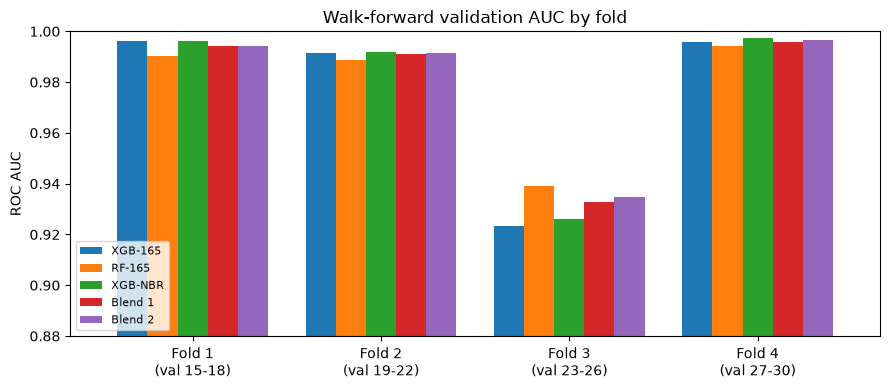

In [24]:
MODELS = {
    "XGB-165": (res_xgb165, hold_xgb165),
    "RF-165": (res_rf, hold_rf),
    "XGB-NBR": (res_xgb, hold_xgb),
    "Blend 1": (res_blend1, p_hold_blend1),
    "Blend 2": (res_blend2, p_hold_blend2),
}
comparison = pd.DataFrame([{
    "model": name,
    **{f"fold{k}": v for k, v in enumerate(res["fold_aucs"], start=1)},
    "cv_mean_auc": res["mean_auc"], "cv_std_auc": res["std_auc"], "cv_objective": res["objective"],
    "holdout_auc": roc_auc_score(y_hold, p_hold),
    "public_lb": LEADERBOARD.get(name, (np.nan, np.nan))[0],
    "private_lb": LEADERBOARD.get(name, (np.nan, np.nan))[1],
} for name, (res, p_hold) in MODELS.items()]).set_index("model")
display(comparison.round(5))

fold_df = comparison[[f"fold{k}" for k in range(1, len(FOLD_DEFS) + 1)]].T
fold_df.index = [f"Fold {k}\n(val {vs}-{ve})" for k, (_, vs, ve) in enumerate(FOLD_DEFS, start=1)]
ax = fold_df.plot.bar(rot=0, width=0.8, figsize=(9, 4))
ax.set_ylim(0.88, 1.0)
ax.set_ylabel("ROC AUC")
ax.set_title("Walk-forward validation AUC by fold")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

The neighbour features improve XGBoost on the CV objective, on the hardest fold (fold 3), on the holdout and on both leaderboards. RF-165 has the best CV objective of any single model but the lowest holdout AUC. Swapping XGB-165 for XGB-NBR improves the blend on CV, the holdout and both leaderboards.

XGB-NBR alone has the highest holdout AUC, but the holdout scores are all close to 1 and don't separate the models much. Blend 2 has the better CV objective and also scored higher than XGB-NBR on both leaderboards, so it was my first selection and XGB-NBR my second.

## 10. Final training and test predictions

RF-165 and XGB-NBR are refit on all labelled transactions (steps 1-35) with 5 seeds. The test transactions' neighbour features come from the `final` stage-1 window in Section 5.4. XGB-NBR's test predictions are my second submission, and Blend 2 combines them with RF-165's.

In [25]:
# RF-165
p_test_rf = np.mean([rf_fit(RF_PARAMS, labeled[FEATURES], labeled["label"], s).predict_proba(test[FEATURES])[:, 1]
                     for s in SEEDS], axis=0)

# XGB-NBR
X_full, y_full = fin["X_tr"], fin["y_tr"]
X_test_s2 = pd.concat([X_all, STAGE1["final"]["nbr"]], axis=1)[COLS_S2][is_test]
assert (nodes.loc[is_test, "txId"].to_numpy() == test["txId"].to_numpy()).all()
spw_final = spw_value(y_full, S2_PARAMS["spw_mode"])
p_test_xgb = np.mean([xgb_model(S2_PARAMS, FINAL_ROUNDS, s, spw_final).fit(X_full, y_full, verbose=False)
                      .predict_proba(X_test_s2)[:, 1] for s in SEEDS], axis=0)

# Blend 2 (both prediction vectors are in test.csv order)
p_test = blend_pooled(p_test_rf, p_test_xgb, BLEND_W_XGB)
print(f"Spearman correlation on test, RF-165 vs XGB-NBR: {spearmanr(p_test_rf, p_test_xgb).correlation:.4f}")

Spearman correlation on test, RF-165 vs XGB-NBR: 0.9024


## 11. Submission files

The code below writes both of my selections for the private leaderboard: `submission_blend2.csv` (Blend 2) and `submission_xgb_nbr.csv` (XGB-NBR).

**A note on the random forest.** XGB-NBR gives identical predictions on every run. RF-165 can vary marginally between runs: `random_state` makes every tree identical, but with `n_jobs=-1` scikit-learn adds up the trees' predictions across threads in whatever order they finish, and floating-point addition depends on the order. So RF-165's predictions can change in the last decimal place (around 1e-16). This only matters where two RF-165 test predictions are tied, because they can then share a rank in one run and get separate ranks in another. A handful of rows in `submission_blend2.csv` can therefore move by about one rank step (0.5 / 15,329, about 3.3e-5) (which should have no meaningful effect on AUC).

In [26]:
assert (test["index"].to_numpy() == sample_sub["index"].to_numpy()).all(), "row order must match sample_submission"
FINAL_PREDICTIONS = {"Blend 2": p_test, "XGB-NBR": p_test_xgb}
for name, p in FINAL_PREDICTIONS.items():
    assert len(p) == len(sample_sub) and np.isfinite(p).all() and p.min() >= 0 and p.max() <= 1
    sub = pd.DataFrame({"index": test["index"], "target": p})
    path = SUBMISSION_FILES[name]
    sub.to_csv(path, index=False)
    print(f"{name}: wrote {path} {sub.shape} | target range {p.min():.4f}-{p.max():.4f}")

Blend 2: wrote submission_blend2.csv (15329, 2) | target range 0.0164-0.9997
XGB-NBR: wrote submission_xgb_nbr.csv (15329, 2) | target range 0.0005-0.9989


## 12. Diagnostics

Thresholded metrics use the threshold that maximises illicit-class F1 on each model's out-of-fold predictions. The blends don't get one, because their scores are ranks within a set and don't carry over from the folds to the holdout.

XGB-165: holdout confusion matrix at threshold 0.535 (rows = true 0/1, columns = predicted 0/1)
[[3561   79]
 [  13  677]]
RF-165: holdout confusion matrix at threshold 0.654 (rows = true 0/1, columns = predicted 0/1)
[[3566   74]
 [  21  669]]
XGB-NBR: holdout confusion matrix at threshold 0.595 (rows = true 0/1, columns = predicted 0/1)
[[3571   69]
 [  11  679]]


,XGB-165,RF-165,XGB-NBR
threshold,0.5350,0.6538,0.5945
holdout_roc_auc,0.9981,0.9972,0.9985
holdout_pr_auc,0.9928,0.9898,0.9940
holdout_f1_illicit,0.9364,0.9337,0.9444
holdout_precision_illicit,0.8955,0.9004,0.9078
holdout_recall_illicit,0.9812,0.9696,0.9841
holdout_mcc,0.9250,0.9215,0.9344


Holdout AUC by time step:


,n,n_illicit,XGB-165,RF-165,XGB-NBR,Blend 1,Blend 2
time_step,,,,,,,
31,710,106,0.9957,0.9949,0.9968,0.9955,0.9953
32,1323,342,0.9997,0.9992,0.9998,0.9995,0.9998
33,441,23,0.9941,0.9941,0.9970,0.9946,0.9965
34,515,37,0.9997,0.9988,0.9998,0.9998,0.9998
35,1341,182,0.9969,0.9951,0.9971,0.9963,0.9965


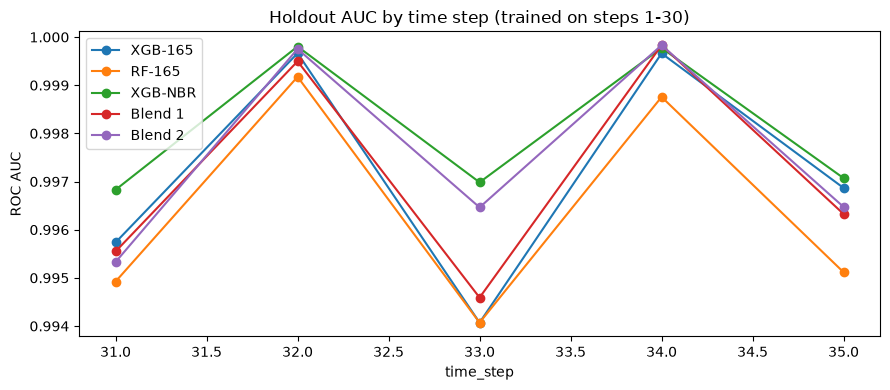

In [27]:
rows = {}
for name, res, p_hold in [("XGB-165", res_xgb165, hold_xgb165), ("RF-165", res_rf, hold_rf), ("XGB-NBR", res_xgb, hold_xgb)]:
    thr, _ = best_f1_threshold(res["oof_y"], res["oof_p"])
    rows[name] = {"threshold": thr, **{f"holdout_{k}": v for k, v in evaluate(y_hold, p_hold, thr).items()}}
    print(f"{name}: holdout confusion matrix at threshold {thr:.3f} (rows = true 0/1, columns = predicted 0/1)")
    print(confusion_matrix(y_hold, (p_hold >= thr).astype(int)))
metrics = pd.DataFrame(rows).round(4)
display(metrics)

steps_hold = hold["time_step"].to_numpy()
step_tbl = per_step_auc(y_hold, hold_rf, steps_hold)[["n", "n_illicit"]]
for name, (_, p_hold) in MODELS.items():
    step_tbl[name] = per_step_auc(y_hold, p_hold, steps_hold)["roc_auc"]
print("Holdout AUC by time step:")
display(step_tbl.round(4))

ax = step_tbl[list(MODELS)].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("ROC AUC")
ax.set_title("Holdout AUC by time step (trained on steps 1-30)")
plt.tight_layout()
plt.show()

In [28]:
# Feature importance of the holdout-window models (trained on steps 1-30)
gain = (pd.concat([pd.Series(m_.get_booster().get_score(importance_type="gain")) for m_ in hold_models_xgb], axis=1)
        .fillna(0).mean(axis=1).reindex(COLS_S2, fill_value=0))
print(f"XGB-NBR: share of total gain from the 5 neighbour features: {gain[NBR_FEATURES].sum() / gain.sum():.1%}")
display(gain.sort_values(ascending=False).head(15).round(1).to_frame("XGB-NBR gain (top 15)"))
display(gain[NBR_FEATURES].sort_values(ascending=False).round(1).to_frame("XGB-NBR gain: neighbour features"))

mdi = pd.Series(np.mean([m_.feature_importances_ for m_ in hold_models_rf], axis=0), index=FEATURES)
display(mdi.sort_values(ascending=False).head(15).round(4).to_frame("RF-165 impurity importance (top 15)"))

XGB-NBR: share of total gain from the 5 neighbour features: 8.6%


,XGB-NBR gain (top 15)
feat_53,999.8
feat_41,955.2
feat_55,800.1
feat_103,624.5
pred_max_p,465.8
pred_mean_p,435.4
feat_18,403.9
feat_100,386.6
feat_47,344.3
feat_43,333.3


,XGB-NBR gain: neighbour features
pred_max_p,465.8
pred_mean_p,435.4
succ_max_p,173.1
succ_mean_p,79.8
hop2_max_p,67.9


,RF-165 impurity importance (top 15)
feat_53,0.2562
feat_90,0.1089
feat_55,0.0737
feat_163,0.0529
feat_47,0.0416
feat_59,0.0374
feat_65,0.0374
feat_41,0.0329
feat_14,0.0320
feat_5,0.0312
